# Sprint 4: Forecast tomorrow's high

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/nyc_daily_1981_2025.csv", index_col="date", parse_dates=True)
df["high_f"] = df["T2M_MAX"] * 9/5 + 32
df[["T2M_MAX", "high_f"]].head()

,T2M_MAX,high_f
date,,
1981-01-01,-1.28,29.696
1981-01-02,1.64,34.952
1981-01-03,-1.33,29.606
1981-01-04,-6.10,21.020
1981-01-05,-2.24,27.968


In [2]:
df["high_f"].describe()

count    16436.000000
mean        58.417136
std         15.625781
min         10.940000
25%         45.482000
50%         58.352000
75%         72.770000
max         93.650000
Name: high_f, dtype: float64

In [3]:
df["tomorrow_high"] = df["high_f"].shift(-1)
df["today_high"] = df["high_f"]
df["yesterday_high"] = df["high_f"].shift(1)
df["two_days_ago_high"] = df["high_f"].shift(2)

data = df.dropna()
data[["two_days_ago_high", "yesterday_high", "today_high", "tomorrow_high"]].head()

,two_days_ago_high,yesterday_high,today_high,tomorrow_high
date,,,,
1981-01-03,29.696,34.952,29.606,21.020
1981-01-04,34.952,29.606,21.020,27.968
1981-01-05,29.606,21.020,27.968,33.746
1981-01-06,21.020,27.968,33.746,36.536
1981-01-07,27.968,33.746,36.536,21.776


In [5]:
len(data)

16433

In [6]:
features = ["two_days_ago_high", "yesterday_high", "today_high"]
target = "tomorrow_high"

train = data.loc[:"2018-12-31"]
test = data.loc["2019-01-01":]

X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]

print(len(train), len(test))

13877 2556


In [7]:
test.index.min(), test.index.max()

(Timestamp('2019-01-01 00:00:00'), Timestamp('2025-12-30 00:00:00'))

In [8]:
from sklearn.metrics import mean_absolute_error

persistence_pred = test["today_high"]
persistence_mae = mean_absolute_error(y_test, persistence_pred)
print(f"Persistence MAE: {persistence_mae:.2f} °F")

Persistence MAE: 3.81 °F


In [11]:
clim = train.groupby(train.index.day_of_year)["tomorrow_high"].mean()

clim_pred = clim.loc[test.index.day_of_year].values
clim_mae = mean_absolute_error(y_test, clim_pred)
print(f"Climatology MAE: {clim_mae:.2f} °F")

Climatology MAE: 4.37 °F


In [12]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)
lr_mae = mean_absolute_error(y_test, lr_pred)
print(f"Linear regression MAE: {lr_mae:.2f} °F")
print(dict(zip(features, lr.coef_.round(2))))

Linear regression MAE: 3.68 °F
{'two_days_ago_high': np.float64(0.23), 'yesterday_high': np.float64(-0.05), 'today_high': np.float64(0.79)}


In [13]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_mae = mean_absolute_error(y_test, rf_pred)
print(f"Random forest MAE: {rf_mae:.2f} °F")

Random forest MAE: 3.75 °F


In [14]:
import numpy as np

data["today_low"] = data["T2M_MIN"] * 9/5 + 32
data["today_humidity"] = data["RH2M"]
data["today_rain"] = data["PRECTOTCORR"]
day = data.index.day_of_year
data["season_sin"] = np.sin(2 * np.pi * day / 365.25)
data["season_cos"] = np.cos(2 * np.pi * day / 365.25)

features2 = features + ["today_low", "today_humidity", "today_rain", "season_sin", "season_cos"]
train, test = data.loc[:"2018-12-31"], data.loc["2019-01-01":]
X_train2, X_test2 = train[features2], test[features2]

In [15]:
from sklearn.linear_model import LinearRegression

lr2 = LinearRegression()
lr2.fit(X_train2, y_train)

lr2_pred = lr2.predict(X_test2)
lr2_mae = mean_absolute_error(y_test, lr2_pred)
print(f"Linear regression MAE: {lr2_mae:.2f} °F")


Linear regression MAE: 3.32 °F


In [16]:
from sklearn.ensemble import RandomForestRegressor

rf2 = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf2.fit(X_train2, y_train)

rf2_pred = rf2.predict(X_test2)
rf2_mae = mean_absolute_error(y_test, rf2_pred)
print(f"Random forest MAE: {rf2_mae:.2f} °F")

Random forest MAE: 3.20 °F


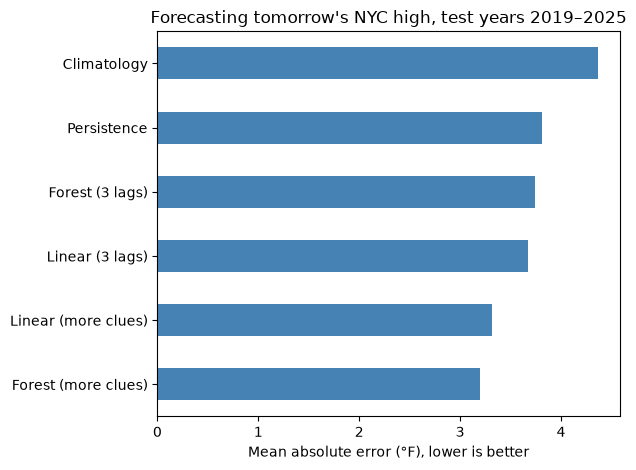

In [18]:
results = pd.Series({
    "Climatology": clim_mae,
    "Persistence": persistence_mae,
    "Linear (3 lags)": lr_mae,
    "Forest (3 lags)": rf_mae,
    "Linear (more clues)": lr2_mae,
    "Forest (more clues)": rf2_mae,
})

results.sort_values().plot(kind="barh", color="steelblue")
plt.xlabel("Mean absolute error (°F), lower is better")
plt.title("Forecasting tomorrow's NYC high, test years 2019–2025")
plt.tight_layout()
plt.show()

## Results

Goal: predict tomorrow's daily high (°F) for the NYC region.
Trained on 1981–2018, tested on 2019–2025 (split by time, no shuffling).

| Model | MAE (°F) |
|---|---|
| Climatology (average for the date) | 4.37 |
| Persistence (tomorrow = today) | 3.81 |
| Linear regression, 3 lags | 3.68 |
| Random forest, 3 lags | 3.75 |
| Linear regression, more clues | 3.32 |
| Random forest, more clues | 3.20 |

**Takeaways**
- "Tomorrow = today" is a tough baseline: only ~3.8°F off on average.
- With only past highs as clues, the random forest was no better than linear regression.
- Adding today's low, humidity, rain, and season helped both models. The forest did best, cutting error ~16% vs. persistence.
- Lesson: better features mattered more than a fancier model.